<a href="https://colab.research.google.com/github/zainaBanglekar/CSL701-Roll_No_-CS03_Machine-Learning-Lab/blob/main/Experiments%20and%20Mini-Project/ML_Experiment_5.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Name : Zaina Mujaveed Banglekar

### Aim : To implement a Bagging (Bootstrap Aggregating) ensemble classifier from scratch using Python, apply it to the Pima Indians Diabetes Database, and evaluate its performance against a single base classifier (Decision Tree)**.


## Objectives

1. Understand Ensemble Learning Principles: Comprehend how combining the predictions of multiple diverse models reduces overall model variance.
2. Master Bootstrapping: Implement random resampling of data with replacement from scratch to generate distinct training subsets.
3. Develop a Voting System: Build an aggregation mechanism (Majority Voting) from scratch to consolidate predictions.
4. Learn Baseline Evaluation: Compare the performance of a high-variance, low-bias single decision tree against the more stable Bagging ensemble.
5. Analyze Performance Metrics: Calculate and visualize classification metrics, including a Confusion Matrix, Accuracy, Precision, Recall, and ROC-AUC curve.


Relevant Theory
Ensemble Methods and Bagging
Ensemble learning combines several individual classifiers (base learners) to produce a unified model that generalizes better than any single model on unseen data. Bootstrap Aggregating (Bagging) is a parallel ensemble method designed primarily to reduce variance. High-variance models—such as deep, fully-grown decision trees—are highly sensitive to small changes in their training datasets. Bagging addresses this by smoothing out individual model errors without increasing bias.

The two core components of Bagging are:

1. Bootstrapping (Sampling with Replacement): For a training set of size $N$, we generate $B$ new datasets of the same size $N$. Each instance is selected at random from the original dataset with replacement. This means a single instance can be selected multiple times, while on average, only about 63.2% of the unique training samples are captured in each bootstrap, leaving the rest as out-of-bag (OOB) samples.
2. Aggregating (Majority Voting): A separate base learner $h_b(x)$ is trained independently on each bootstrap sample. For classification, predictions are aggregated by passing a test sample to all $B$ models and taking a majority vote: $$\hat{G}{\text{bag}}(x) = \text{argmax}{k} \sum_{b=1}^{B} I(h_b(x) = k)$$

An alternative to standard Bagging is subagging (subsample aggregating), where smaller training subsets (often $N/2$) are drawn without replacement to reduce correlation and accelerate computation.

---
## Software Requirements

- **Language:** Python 3.x

- **Core Libraries:**
  - **NumPy** for matrix manipulation and custom bootstrapping operations.
  - **Pandas** for loading, indexing, and cleaning tabular data.
  - **Matplotlib / Seaborn** for exploratory scatter plots, bar charts, and performance visualization.
  - **Scikit-learn** for train-test splitting, training individual base decision trees, and comparison with built-in Bagging algorithms.

---

## Dataset Information

The experiment utilizes the **Pima Indians Diabetes Database** from the UCI Machine Learning Repository. The dataset contains medical details for 768 female Pima Indian patients living in Arizona, categorized as either diabetic or non-diabetic.

- **Total Instances:** 768

- **Features (8 predictor variables):**
  1. **`Pregnancies`**: Number of times pregnant.
  2. **`Glucose`**: Plasma glucose concentration over 2 hours in an oral glucose tolerance test.
  3. **`BloodPressure`**: Diastolic blood pressure (mm Hg).
  4. **`SkinThickness`**: Triceps skin fold thickness (mm).
  5. **`Insulin`**: 2-Hour serum insulin ($\mu$U/ml).
  6. **`BMI`**: Body mass index (weight in kg/m$^2$).
  7. **`DiabetesPedigreeFunction`**: A function representing genetic predisposition.
  8. **`Age`**: Age of the subject in years.

- **Target Label (9th column):** **`Outcome`**
  - **0** represents non-diabetic.
  - **1** represents diabetic.

## Experimental Tasks

### Task 1: Environment Setup and Dataset Acquisition

**Goal:** Set up the workspace and load the data.

**Instructions:**

1. Import the necessary modules: **`numpy`**, **`pandas`**, **`matplotlib.pyplot`**, and **`sklearn`**.

2. Load the file **`pima-indians-diabetes.data`** into a Pandas DataFrame, assigning appropriate column headers.

3. Print the following:
   - First five records of the dataset.
   - Dataset shape, expected to be $768 \times 9$.
   - Data types of all features.
   - Descriptive statistics of the numeric features.

In [39]:
# ==========================================
# Task 1: Environment Setup and Dataset Acquisition
# ==========================================

# Import necessary libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn

# Display sklearn version
print("Scikit-learn version:", sklearn.__version__)

# Column names for Pima Indians Diabetes Dataset
columns = [
    "Pregnancies",
    "Glucose",
    "BloodPressure",
    "SkinThickness",
    "Insulin",
    "BMI",
    "DiabetesPedigreeFunction",
    "Age",
    "Outcome"
]

# Load the dataset - skipping the header row to ensure numeric types
df = pd.read_csv(
    "diabetes.csv",
    header=0,
    names=columns
)

# 1. Display first five records
print("\nFirst five records:")
display(df.head())

# 2. Display dataset shape
print("\nDataset Shape:")
print(df.shape)

# 3. Display data types
print("\nData Types of all features:")
print(df.dtypes)

# 4. Descriptive statistics
print("\nDescriptive Statistics:")
display(df.describe())

Scikit-learn version: 1.6.1

First five records:


,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148,72.0,35,169.5,33.6,0.627,50,1
1,1,85,66.0,29,102.5,26.6,0.351,31,0
2,8,183,64.0,32,169.5,23.3,0.672,32,1
3,1,89,66.0,23,94.0,28.1,0.167,21,0
4,0,137,40.0,35,168.0,43.1,2.288,33,1



Dataset Shape:
(768, 9)

Data Types of all features:
Pregnancies                   int64
Glucose                       int64
BloodPressure               float64
SkinThickness                 int64
Insulin                     float64
BMI                         float64
DiabetesPedigreeFunction    float64
Age                           int64
Outcome                       int64
dtype: object

Descriptive Statistics:


,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
count,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000
mean,3.845052,121.677083,72.389323,29.089844,141.753906,32.434635,0.471876,33.240885,0.348958
std,3.369578,30.464161,12.106039,8.890820,89.100847,6.880498,0.331329,11.760232,0.476951
min,0.000000,44.000000,24.000000,7.000000,14.000000,18.200000,0.078000,21.000000,0.000000
25%,1.000000,99.750000,64.000000,25.000000,102.500000,27.500000,0.243750,24.000000,0.000000
50%,3.000000,117.000000,72.000000,28.000000,102.500000,32.050000,0.372500,29.000000,0.000000
75%,6.000000,140.250000,80.000000,32.000000,169.500000,36.600000,0.626250,41.000000,1.000000
max,17.000000,199.000000,122.000000,99.000000,846.000000,67.100000,2.420000,81.000000,1.000000


## Task 2: Exploratory Data Analysis (EDA)

**Goal:** Visually inspect feature distributions and class balance.

**Instructions:**

1. Calculate the **absolute count** and **percentage** of diabetic (`Outcome = 1`) and non-diabetic (`Outcome = 0`) cases. Plot the class balance using a **bar chart**.

2. Create a **scatter plot** of **`Age`** (Feature 7) against **`Glucose`** (Feature 1), color-coded according to the target variable **`Outcome`**.

3. Briefly explain why a simple linear decision boundary is insufficient to clearly separate the diabetic and non-diabetic classes.

Class Distribution:
         Count  Percentage (%)
Outcome                       
0          500       65.104167
1          268       34.895833


/tmp/ipykernel_412/3985571230.py:12: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x='Outcome', data=df, palette='viridis')


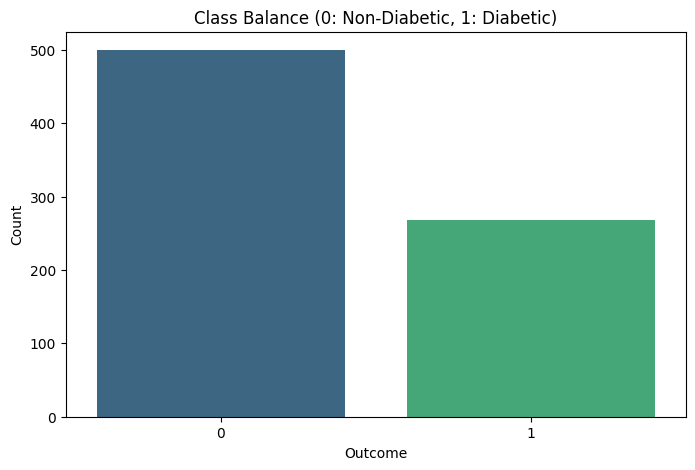

In [40]:
import seaborn as sns

# 1. Calculate absolute count and percentage
counts = df['Outcome'].value_counts()
percentages = df['Outcome'].value_counts(normalize=True) * 100

print("Class Distribution:")
print(pd.DataFrame({'Count': counts, 'Percentage (%)': percentages}))

# Plot class balance
plt.figure(figsize=(8, 5))
sns.countplot(x='Outcome', data=df, palette='viridis')
plt.title('Class Balance (0: Non-Diabetic, 1: Diabetic)')
plt.xlabel('Outcome')
plt.ylabel('Count')
plt.show()

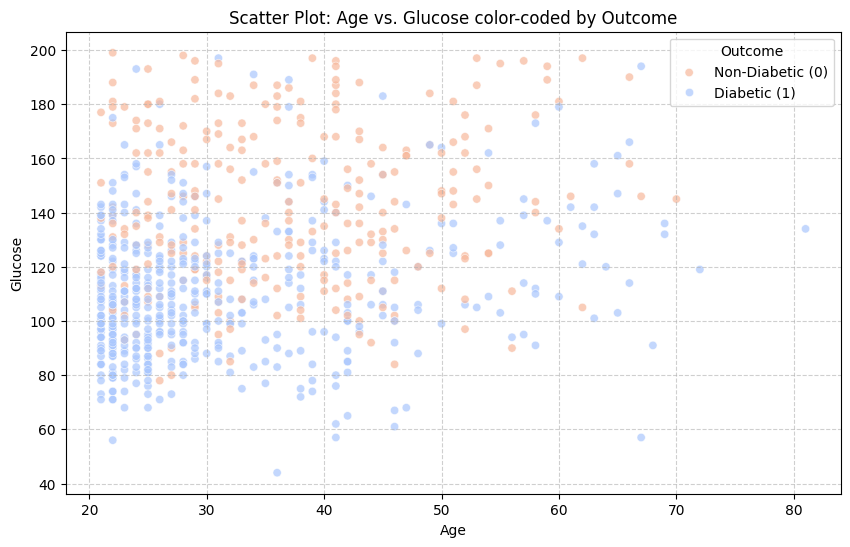

In [41]:
# 2. Scatter plot of Age vs Glucose
plt.figure(figsize=(10, 6))
sns.scatterplot(x='Age', y='Glucose', hue='Outcome', data=df, palette='coolwarm', alpha=0.7)
plt.title('Scatter Plot: Age vs. Glucose color-coded by Outcome')
plt.xlabel('Age')
plt.ylabel('Glucose')
plt.legend(title='Outcome', labels=['Non-Diabetic (0)', 'Diabetic (1)'])
plt.grid(True, linestyle='--', alpha=0.6)
plt.show()

### 3. Analysis of Decision Boundary

Based on the scatter plot of **Age vs. Glucose**, a simple linear decision boundary is insufficient because:

*   **Class Overlap:** There is significant overlap between the diabetic (1) and non-diabetic (0) data points across the middle ranges of both Age and Glucose. A single straight line cannot separate the two groups without a high number of misclassifications.
*   **Non-Linearity:** The relationship between these features and the onset of diabetes is likely non-linear and influenced by other features (like BMI or Insulin), requiring more complex models like Decision Trees or Ensembles to capture the decision surface.

In [42]:
# 1. Identify features where 0 is physically impossible
missing_features = ['Glucose', 'BloodPressure', 'SkinThickness', 'Insulin', 'BMI']

# 2. Ensure columns are numeric (converting errors to NaN if necessary)
for feature in missing_features:
    df[feature] = pd.to_numeric(df[feature], errors='coerce')

# 3. Replace invalid 0 values with NaN
df[missing_features] = df[missing_features].replace(0, np.nan)

# 4. Handle missing values by imputing them using the median of the respective feature
for feature in missing_features:
    median_value = df[feature].median()
    df[feature] = df[feature].fillna(median_value)

# Verify that there are no remaining missing values
print("Missing values after median imputation:")
print(df[missing_features].isnull().sum())

Missing values after median imputation:
Glucose          0
BloodPressure    0
SkinThickness    0
Insulin          0
BMI              0
dtype: int64


#### **Task 3: Preprocessing and Handling Missing Values**

**Goal:** Handle anomalies and prepare numerical features for further analysis.

**Instructions:**

1. Identify the features where a value of \(0\) is physically impossible:
   \[
   \{\text{Glucose},\text{BloodPressure},\text{SkinThickness},
   \text{Insulin},\text{BMI}\}
   \]

2. Replace all invalid \(0\) values in these features with \(\mathrm{NaN}\).

3. Handle the resulting missing values by:
   - imputing them using the **mean** or **median** of the respective feature, or
   - dropping rows containing missing values to maintain numerical consistency.

In [43]:
# 1. Identify features where 0 is physically impossible
missing_features = ['Glucose', 'BloodPressure', 'SkinThickness', 'Insulin', 'BMI']

# 2. Replace invalid 0 values in these features with NaN
df[missing_features] = df[missing_features].replace(0, np.nan)

# 3. Handle missing values by imputing them using the median of each feature
for feature in missing_features:
    median_val = df[feature].median()
    df[feature] = df[feature].fillna(median_val)

# 4. Verification
print("Missing values after median imputation:")
print(df[missing_features].isnull().sum())
print("\nSummary statistics after imputation:")
display(df[missing_features].describe())

Missing values after median imputation:
Glucose          0
BloodPressure    0
SkinThickness    0
Insulin          0
BMI              0
dtype: int64

Summary statistics after imputation:


,Glucose,BloodPressure,SkinThickness,Insulin,BMI
count,768.000000,768.000000,768.000000,768.000000,768.000000
mean,121.677083,72.389323,29.089844,141.753906,32.434635
std,30.464161,12.106039,8.890820,89.100847,6.880498
min,44.000000,24.000000,7.000000,14.000000,18.200000
25%,99.750000,64.000000,25.000000,102.500000,27.500000
50%,117.000000,72.000000,28.000000,102.500000,32.050000
75%,140.250000,80.000000,32.000000,169.500000,36.600000
max,199.000000,122.000000,99.000000,846.000000,67.100000


#### **Task 4: Stratified Train-Test Splitting**

**Goal:** Divide the data while preserving class proportions.

**Instructions:**

1. Isolate the feature matrix \(X\) and the target vector \(y\):
   \[
   X = \text{first 8 columns}
   \]
   \[
   y = \text{9th column}
   \]

2. Split the dataset into:
   \[
   \text{Training Data} = 80\%
   \]
   \[
   \text{Test Data} = 20\%
   \]

   Use **stratified sampling** to ensure that the class proportions in the target variable \(y\) are preserved in both the training and test datasets.

In [44]:
from sklearn.model_selection import train_test_split

# 1. Clean the data: remove header row if it exists as data
# Based on the kernel state, the first row (index 0) contains column names as strings
if df.iloc[0]['Outcome'] == 'Outcome':
    df = df.iloc[1:].reset_index(drop=True)

# 2. Ensure the target variable 'Outcome' is numeric for stratification
df['Outcome'] = pd.to_numeric(df['Outcome'])

# 3. Isolate the feature matrix X and the target vector y
X = df.drop('Outcome', axis=1)
y = df['Outcome']

# 4. Split the dataset into 80% Training and 20% Test Data
# Using stratified sampling
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=42
)

print("Training set shape:", X_train.shape)
print("Test set shape:", X_test.shape)
print("\nClass proportions in Training set:\n", y_train.value_counts(normalize=True))
print("\nClass proportions in Test set:\n", y_test.value_counts(normalize=True))

Training set shape: (614, 8)
Test set shape: (154, 8)

Class proportions in Training set:
 Outcome
0    0.651466
1    0.348534
Name: proportion, dtype: float64

Class proportions in Test set:
 Outcome
0    0.649351
1    0.350649
Name: proportion, dtype: float64


#### **Task 5: Custom Bootstrap Sampling Function**

**Goal:** Implement the sampling-with-replacement mechanism.

**Instructions:**

1. Write a custom Python function \(\texttt{get\_bootstrap\_sample}(X, y)\) using NumPy's random generation tools, such as:
   \[
   \texttt{np.random.choice}
   \quad \text{or} \quad
   \texttt{np.random.randint}
   \]

2. The function must return a resampled feature matrix \(X^*\) and target vector \(y^*\) of the same size \(N\) as the training set:
   \[
   |X^*| = |y^*| = N
   \]
   
   Sampling should be performed **with replacement**, allowing duplicate rows to appear in the bootstrap sample.

3. Verify that the function works correctly by demonstrating that:
   - Some original row indices are **duplicated** in the bootstrap sample.
   - Some original row indices are **omitted**, forming the **Out-of-Bag (OOB)** samples.

In [45]:
def get_bootstrap_sample(X, y):
    """
    Generates a bootstrap sample from the training data.
    Returns X_resampled and y_resampled of the same size N.
    """
    n_samples = X.shape[0]
    # Generate random indices with replacement
    indices = np.random.choice(n_samples, size=n_samples, replace=True)

    X_resampled = X.iloc[indices]
    y_resampled = y.iloc[indices]

    return X_resampled, y_resampled, indices

# Verification
X_boot, y_boot, boot_indices = get_bootstrap_sample(X_train, y_train)

unique_indices = len(np.unique(boot_indices))
duplicates = len(boot_indices) - unique_indices
oob_count = len(X_train) - unique_indices

print(f"Original training size: {len(X_train)}")
print(f"Number of unique indices in bootstrap: {unique_indices}")
print(f"Number of duplicated records: {duplicates}")
print(f"Number of Out-of-Bag (OOB) records: {oob_count}")

Original training size: 614
Number of unique indices in bootstrap: 384
Number of duplicated records: 230
Number of Out-of-Bag (OOB) records: 230


#### **Task 6: Growing the Ensemble of Base Classifiers**

**Goal:** Programmatically train diverse base learners.

**Instructions:**

1. Initialize an empty list to store the trained models and choose the number of bootstrap iterations, for example:
   \[
   B = 50
   \]

2. Execute the following steps for \(B\) iterations:

   - Generate a unique bootstrap training dataset:
     \[
     (X^{*b}, y^{*b})
     \]
     using the bootstrap sampling function from **Task 5**.

   - Instantiate a Scikit-Learn `DecisionTreeClassifier` with:
     \[
     \texttt{max\_depth=None}
     \]
     This ensures that the decision trees are **fully grown**, resulting in high-variance base learners.

   - Fit the decision tree on the bootstrapped training subset:
     \[
     \text{Model}_b.fit(X^{*b}, y^{*b})
     \]

   - Append the trained model to the ensemble list.

3. After completing all \(B\) iterations, the ensemble should contain:
   \[
   B = 50
   \]
   independently trained decision trees.

In [46]:
from sklearn.tree import DecisionTreeClassifier

# 1. Settings
B = 50
ensemble = []

# 2. Grow the ensemble
for i in range(B):
    # Generate a unique bootstrap training dataset
    X_star, y_star, _ = get_bootstrap_sample(X_train, y_train)

    # Instantiate a fully grown DecisionTreeClassifier
    tree = DecisionTreeClassifier(max_depth=None, random_state=i)

    # Fit the model
    tree.fit(X_star, y_star)

    # Append to the ensemble
    ensemble.append(tree)

print(f"Ensemble training complete. Total trees: {len(ensemble)}")

Ensemble training complete. Total trees: 50


#### **Task 7: Implementing Aggregation (Majority Voting) from Scratch**

**Goal:** Consolidate individual model decisions using majority voting.

**Instructions:**

1. Write a custom function:
   \[
   \texttt{custom\_bagging\_predict(ensemble, X\_test)}
   \]
   to generate the final predictions.

2. For each sample in \(X_{\text{test}}\), collect the predictions generated by all \(B\) decision trees in the ensemble:
   \[
   \hat{y}_1,\hat{y}_2,\ldots,\hat{y}_B
   \]

3. Apply a **majority voting** rule to determine the final predicted class. The class with the highest number of votes is selected:
   \[
   \hat{y} =
   \underset{c \in \{0,1\}}{\arg\max}
   \sum_{b=1}^{B} I(\hat{y}_b=c)
   \]

   where \(I(\cdot)\) is an indicator function.

4. The final prediction for each test sample must therefore be either:
   \[
   \hat{y} \in \{0,1\}
   \]

5. The function should return the final majority-voted predictions for all samples in \(X_{\text{test}}\).

In [47]:
def custom_bagging_predict(ensemble, X_test):
    """
    Generates final predictions using majority voting across the ensemble.
    """
    # 1. Collect predictions from each tree
    # Each row will be a tree's predictions for all test samples
    predictions = np.array([tree.predict(X_test) for tree in ensemble])

    # 2. Apply majority voting for each sample (column-wise)
    # We take the mode along the rows (axis 0)
    from scipy import stats
    mode_result = stats.mode(predictions, axis=0, keepdims=True)
    final_predictions = mode_result.mode.flatten()

    return final_predictions

# Generate predictions for the test set
y_pred_bagging = custom_bagging_predict(ensemble, X_test)

print("Predictions generated for", len(y_pred_bagging), "test samples.")
print("First 10 predictions:", y_pred_bagging[:10])

Predictions generated for 154 test samples.
First 10 predictions: [0 0 0 1 0 0 1 1 0 1]


#### **Task 8: Single Classifier vs. Bagging Performance Comparison**

- **Goal:** Observe the variance-reduction benefits of ensembling.

- **Instructions:**
  1. Train a standalone, single \(\texttt{DecisionTreeClassifier}\) (fully grown, no depth limit) on the original, un-resampled training data.
  2. Predict the classes for \(X_{\text{test}}\) using both the single tree and your custom Bagging classifier.
  3. Construct a **Confusion Matrix** for both models.
  4. Compute and print **Accuracy, Precision, Recall, and F1-Score** for both models, demonstrating how Bagging stabilizes results and reduces error rates.

In [49]:
from sklearn.metrics import confusion_matrix, accuracy_score, precision_score, recall_score, f1_score

# 1. Train a standalone single Decision Tree
single_tree = DecisionTreeClassifier(max_depth=None, random_state=42)
single_tree.fit(X_train, y_train)

# 2. Predict using the single tree
y_pred_single = single_tree.predict(X_test)

# 3. Evaluation Function
def evaluate_model(y_true, y_pred, name):
    acc = accuracy_score(y_true, y_pred)
    prec = precision_score(y_true, y_pred)
    rec = recall_score(y_true, y_pred)
    f1 = f1_score(y_true, y_pred)
    cm = confusion_matrix(y_true, y_pred)

    print(f"--- {name} Performance ---")
    print(f"Accuracy:  {acc:.4f}")
    print(f"Precision: {prec:.4f}")
    print(f"Recall:    {rec:.4f}")
    print(f"F1-Score:  {f1:.4f}")
    print("Confusion Matrix:")
    print(cm)
    print("\n")
    return cm

# 4. Compare Models
cm_single = evaluate_model(y_test, y_pred_single, "Single Decision Tree")
cm_bagging = evaluate_model(y_test, y_pred_bagging, "Custom Bagging Ensemble")

--- Single Decision Tree Performance ---
Accuracy:  0.8117
Precision: 0.7451
Recall:    0.7037
F1-Score:  0.7238
Confusion Matrix:
[[87 13]
 [16 38]]


--- Custom Bagging Ensemble Performance ---
Accuracy:  0.8831
Precision: 0.8600
Recall:    0.7963
F1-Score:  0.8269
Confusion Matrix:
[[93  7]
 [11 43]]




#### **Task 9: ROC-AUC Analysis and Curve Visualization**

- **Goal:** Measure classification performance at different thresholds.

- **Instructions:**
  1. Calculate predicted class probabilities by averaging the probability estimates (\(\texttt{predict\_proba}\)) across all \(B\) decision trees in your custom Bagging model.
  2. Plot the **Receiver Operating Characteristic (ROC) curve** for both the single decision tree and the custom Bagging model on a single chart.
  3. Compute and contrast the **Area Under the Curve (AUC)** for both configurations, noting the improvement.

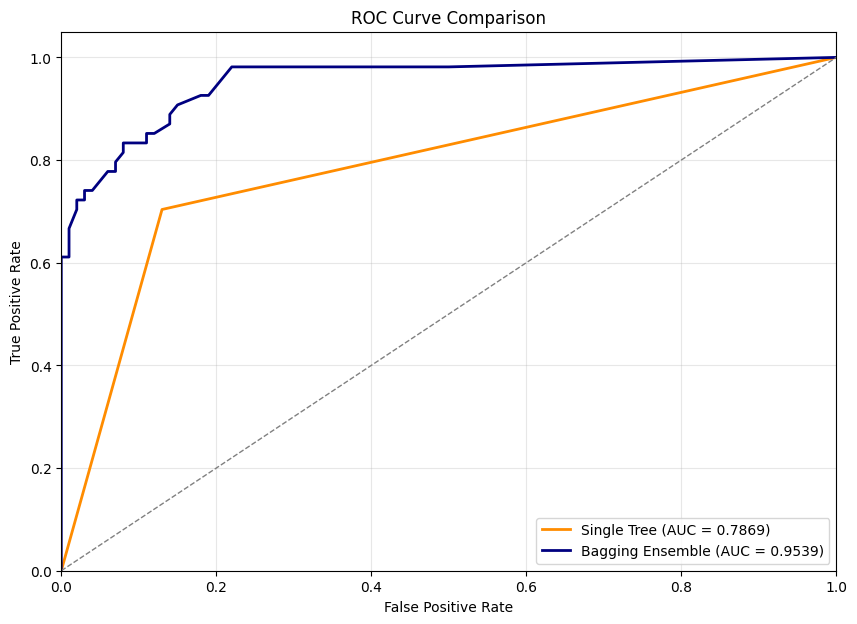

Single Tree AUC: 0.7869
Bagging Ensemble AUC: 0.9539


In [50]:
from sklearn.metrics import roc_curve, auc

# 1. Calculate probabilities for Single Decision Tree
y_probs_single = single_tree.predict_proba(X_test)[:, 1]

# 2. Calculate average probabilities across the ensemble for Bagging
# Collect predict_proba from each tree and average them
all_tree_probs = np.array([tree.predict_proba(X_test)[:, 1] for tree in ensemble])
y_probs_bagging = np.mean(all_tree_probs, axis=0)

# 3. Compute ROC curve and AUC for both
fpr_s, tpr_s, _ = roc_curve(y_test, y_probs_single)
roc_auc_s = auc(fpr_s, tpr_s)

fpr_b, tpr_b, _ = roc_curve(y_test, y_probs_bagging)
roc_auc_b = auc(fpr_b, tpr_b)

# 4. Plot the ROC Curves
plt.figure(figsize=(10, 7))
plt.plot(fpr_s, tpr_s, color='darkorange', lw=2, label=f'Single Tree (AUC = {roc_auc_s:.4f})')
plt.plot(fpr_b, tpr_b, color='navy', lw=2, label=f'Bagging Ensemble (AUC = {roc_auc_b:.4f})')
plt.plot([0, 1], [0, 1], color='gray', lw=1, linestyle='--')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve Comparison')
plt.legend(loc="lower right")
plt.grid(alpha=0.3)
plt.show()

print(f"Single Tree AUC: {roc_auc_s:.4f}")
print(f"Bagging Ensemble AUC: {roc_auc_b:.4f}")

#### **Task 10: Validation against Scikit-Learn's BaggingClassifier**

- **Goal:** Verify custom code correctness.

- **Instructions:**
  1. Instantiate Scikit-Learn's built-in \(\texttt{BaggingClassifier}\) using \(\texttt{DecisionTreeClassifier(max\_depth=None)}\) as the base estimator and \(\texttt{n\_estimators=50}\).
  2. Fit the classifier on the training set and evaluate it on the test set.
  3. Compare the resulting test accuracy and confusion matrix against your custom implementation from **Task 7** and **Task 8** to validate your custom bootstrap and aggregation logic.

In [51]:
from sklearn.ensemble import BaggingClassifier

# 1. Instantiate Scikit-Learn's BaggingClassifier
sk_bagging = BaggingClassifier(
    estimator=DecisionTreeClassifier(max_depth=None),
    n_estimators=50,
    random_state=42
)

# 2. Fit on the training set
sk_bagging.fit(X_train, y_train)

# 3. Predict and evaluate
y_pred_sk = sk_bagging.predict(X_test)
cm_sk = evaluate_model(y_test, y_pred_sk, "Scikit-Learn BaggingClassifier")

# 4. Compare with custom implementation results
print(f"Custom Bagging Accuracy: {accuracy_score(y_test, y_pred_bagging):.4f}")
print(f"Sklearn Bagging Accuracy: {accuracy_score(y_test, y_pred_sk):.4f}")

--- Scikit-Learn BaggingClassifier Performance ---
Accuracy:  0.8831
Precision: 0.8333
Recall:    0.8333
F1-Score:  0.8333
Confusion Matrix:
[[91  9]
 [ 9 45]]


Custom Bagging Accuracy: 0.8831
Sklearn Bagging Accuracy: 0.8831


### **Conclusion and Interpretation**

Students should summarize their findings by answering the following key questions:

1. **Variance and Stability:** How does the test accuracy of the Bagging ensemble compare to the single decision tree? Why does Bagging provide more consistent performance across different train-test splits?

2. **Wisdom of Crowds:** How does random resampling with replacement (bootstrapping) foster model diversity, and how does the consensus voting rule translate to a "Wisdom of Crowds" effect?

3. **Clinical Interpretation:** In predicting diabetes, why are False Negatives (predicting non-diabetic for a diabetic patient) especially costly, and how does Bagging's Recall metric help minimize this risk compared to a single decision tree?